<a href="https://colab.research.google.com/github/aamyardra-rgb/TEXT-AND-IMAGE-PROCESSING/blob/main/NLP_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

In [ ]:
df=pd.read_csv('/content/twitter_validation.csv',header = None,encoding='ISO-8859-1')
df

,0,1,2,3
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.columns=['id','media','target','text']
df

,id,media,target,text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.shape

(1000, 4)

In [ ]:
df.size

4000

In [ ]:
df.head()

,id,media,target,text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...


In [ ]:
df.tail()

,id,media,target,text
995,4891,GrandTheftAuto(GTA),Irrelevant,â­ï¸ Toronto is the arts and culture capital...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.
999,6960,johnson&johnson,Neutral,Johnson & Johnson to stop selling talc baby po...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      1000 non-null   int64 
 1   media   1000 non-null   object
 2   target  1000 non-null   object
 3   text    1000 non-null   object
dtypes: int64(1), object(3)
memory usage: 31.4+ KB


In [ ]:
df.describe()

,id
count,1000.000000
mean,6432.088000
std,3728.310569
min,6.000000
25%,3247.750000
50%,6550.000000
75%,9661.750000
max,13197.000000


In [ ]:
df.dtypes

,0
id,int64
media,object
target,object
text,object


In [ ]:
df.isna().sum()

,0
id,0
media,0
target,0
text,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df1= df['target'].value_counts()
df1

,count
target,
Neutral,285
Positive,277
Negative,266
Irrelevant,172


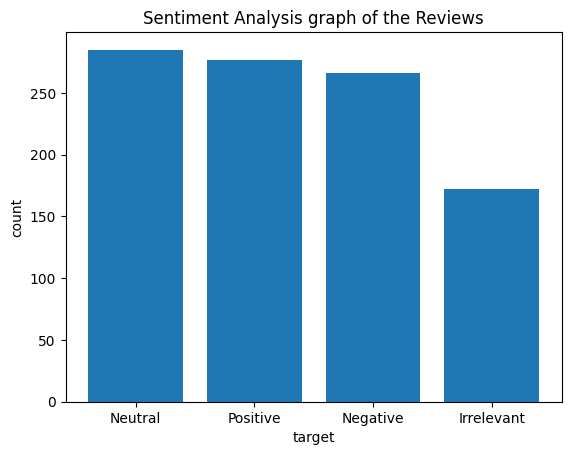

In [ ]:
plt.bar(df1.index,df1.values)
plt.xlabel('target')
plt.ylabel('count')
plt.title('Sentiment Analysis graph of the Reviews')
plt.show()

In [ ]:
df.drop(df.index[(df['target']=='Irrelevant')],axis = 0,inplace = True)
df

,id,media,target,text
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
5,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
993,314,Amazon,Negative,Please explain how this is possible! How can t...
994,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
997,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.reset_index(drop = True,inplace= True)
df

,id,media,target,text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...,...,...
823,314,Amazon,Negative,Please explain how this is possible! How can t...
824,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
825,2652,Borderlands,Positive,Today sucked so itâs time to drink wine n pl...
826,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.drop(['id','media'],axis=1,inplace=True)
df

,target,text
0,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,Negative,@Microsoft Why do I pay for WORD when it funct...
2,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,Neutral,Now the President is slapping Americans in the...
4,Negative,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,Negative,Please explain how this is possible! How can t...
824,Positive,Good on Sony. As much as I want to see the new...
825,Positive,Today sucked so itâs time to drink wine n pl...
826,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
# target to numeric
# Positive :1
# Negative :-1
# Neutral  :0

# map function can be used

df['target']=df['target'].map({'Positive':1,'Negative':-1,'Neutral':0})
df

,target,text
0,0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,-1,@Microsoft Why do I pay for WORD when it funct...
2,-1,"CSGO matchmaking is so full of closet hacking,..."
3,0,Now the President is slapping Americans in the...
4,-1,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...,...
823,-1,Please explain how this is possible! How can t...
824,1,Good on Sony. As much as I want to see the new...
825,1,Today sucked so itâs time to drink wine n pl...
826,1,Bought a fraction of Microsoft today. Small wins.


In [ ]:
tweet = df.text
tweet

,text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,"CSGO matchmaking is so full of closet hacking,..."
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâve had Madeleine McCann in my c...
...,...
823,Please explain how this is possible! How can t...
824,Good on Sony. As much as I want to see the new...
825,Today sucked so itâs time to drink wine n pl...
826,Bought a fraction of Microsoft today. Small wins.


In [ ]:
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
# Tokenization
from nltk.tokenize import TweetTokenizer
tk = TweetTokenizer()
tweet = tweet.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
tweet

#[BBC,News,Amazon,...]  -after tokenize
#[BBC News Amazon] - after joining the space between tokens.

,text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi @EAHelp Iâ   ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible ! How can ...
824,Good on Sony . As much as I want to see the ne...
825,Today sucked so itâ   s time to drink wine n...
826,Bought a fraction of Microsoft today . Small w...


In [ ]:
# Remove special characters

#re.sub('[^a-zA-Z0-9]',' ',tweet)

tweet = tweet.str.replace('[^a-zA-Z0-9]',' ',regex=True)
tweet

,text
0,BBC News Amazon boss Jeff Bezos rejects clai...
1,Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi EAHelp I ve had Madeleine McCann in m...
...,...
823,Please explain how this is possible How can ...
824,Good on Sony As much as I want to see the ne...
825,Today sucked so it s time to drink wine n...
826,Bought a fraction of Microsoft today Small w...


In [ ]:
# minimum characters for a meaningful word = 3 characters
# removing words without min number of characters

tweet = tweet.apply(lambda x:' '.join([w for w  in tk.tokenize(x)if len(w)>=3]))

In [ ]:
# Stemming

from nltk.stem import SnowballStemmer
st = SnowballStemmer('english')
tweet=tweet.apply(lambda x:[st.stem(i.lower())for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
tweet

,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay for word when function poor ...
2,csgo matchmak full closet hack truli aw game
3,now the presid slap american the face that rea...
4,eahelp had madelein mccann cellar for the past...
...,...
823,pleas explain how this possibl how can they le...
824,good soni much want see the new ps5 what go ri...
825,today suck time drink wine play borderland unt...
826,bought fraction microsoft today small win


In [ ]:
# Removing stopwords
from nltk.corpus import stopwords
stop = stopwords.words("english")

tweet = tweet.apply(lambda x : " ".join([i.lower() for i in tk.tokenize(x) if i.lower() not in stop]))
tweet


,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay word function poor samsungus...
2,csgo matchmak full closet hack truli aw game
3,presid slap american face realli commit unlaw ...
4,eahelp madelein mccann cellar past year littl ...
...,...
823,pleas explain possibl let compani overcharg sc...
824,good soni much want see new ps5 go right much ...
825,today suck time drink wine play borderland sun...
826,bought fraction microsoft today small win


In [ ]:
# Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(tweet)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10461 stored elements and shape (828, 3763)>

In [ ]:
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10461 stored elements and shape (828, 3763)>
  Coords	Values
  (0, 515)	0.49155204783978756
  (0, 2267)	0.38864111655856126
  (0, 353)	0.1515362387424402
  (0, 610)	0.22681557001542715
  (0, 1813)	0.24577602391989378
  (0, 545)	0.2608257828483461
  (0, 2741)	0.2608257828483461
  (0, 785)	0.21432663830218204
  (0, 838)	0.17354914655342313
  (0, 286)	0.22681557001542715
  (0, 1976)	0.13277165480466424
  (0, 1108)	0.23509805002803952
  (0, 982)	0.2608257828483461
  (0, 668)	0.2608257828483461
  (1, 2135)	0.24555654927912696
  (1, 3619)	0.26216072802580975
  (1, 2442)	0.3126902562590763
  (1, 3659)	0.36557591217188057
  (1, 1383)	0.4055823664694651
  (1, 2538)	0.3821800909185634
  (1, 2871)	0.4055823664694651
  (1, 775)	0.4055823664694651
  (2, 934)	0.3041178383627944
  (2, 2085)	0.3963165794888645
  (2, 1380)	0.3790982275064499
  :	:
  (825, 3363)	0.2560582225152133
  (825, 3373)	0.3395996844494918
  (825, 826)	0.25069214907989

In [ ]:
# data >> input
# target >> output

y=df['target'].values
y

array([ 0, -1, -1,  0, -1,  1,  1,  1, -1,  1,  1, -1,  0, -1,  1,  1, -1,
        1, -1, -1,  0, -1,  0,  0, -1, -1,  1,  1, -1,  1, -1,  0,  0,  1,
        0,  1,  0,  0,  0,  1,  0, -1, -1, -1,  0,  1, -1, -1,  1,  1,  1,
        1,  1, -1, -1,  1,  1, -1,  0, -1,  0, -1,  1, -1, -1,  1,  1,  1,
        0,  0,  0,  1,  1,  0,  1,  0, -1, -1,  0,  0, -1,  1, -1, -1, -1,
        0,  1,  0, -1,  1,  1,  0,  1,  0,  1, -1,  0,  0,  0, -1,  0, -1,
        0,  0,  1,  1,  0, -1, -1,  1, -1,  0, -1,  1,  0, -1,  0,  1,  0,
        1,  1,  0,  0,  0,  0,  1,  0,  1,  1, -1,  0,  0,  0,  0, -1,  0,
        1, -1,  0, -1,  0, -1, -1, -1,  1,  1,  1,  0,  0,  1,  0,  0,  0,
        1,  0, -1, -1,  0,  1,  1,  0,  1,  1,  0,  0, -1, -1, -1, -1,  1,
        0,  0,  1,  1,  1,  1, -1,  1,  1,  0, -1, -1, -1,  1,  1, -1, -1,
        1,  1, -1,  1,  1, -1,  1,  0, -1,  0,  0,  1, -1,  1,  1,  0,  1,
       -1, -1,  1,  1,  1,  1,  0,  0,  1, -1,  0,  1,  0, -1,  0,  0, -1,
        1,  1, -1,  0,  1

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(data,y,test_size=0.30,random_state=42)
x_train

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 7222 stored elements and shape (579, 3763)>

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=7)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
y_pred

array([-1, -1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1, -1, -1, -1,
        0, -1, -1, -1,  0,  0,  1, -1,  1, -1, -1, -1,  1, -1, -1, -1, -1,
        1, -1,  1, -1, -1, -1, -1,  1,  0,  1, -1,  1,  1,  0, -1, -1, -1,
       -1, -1, -1,  0,  0,  1, -1,  0,  0,  1, -1,  0,  0, -1,  0,  1,  0,
       -1, -1, -1,  0, -1,  1,  1, -1, -1, -1, -1,  1, -1, -1, -1, -1,  0,
       -1, -1,  1,  1, -1, -1, -1, -1, -1,  0,  0, -1,  0,  0, -1, -1,  0,
        0,  0, -1, -1,  1,  0,  0, -1,  0, -1,  1, -1,  1, -1, -1,  1, -1,
       -1,  0,  1, -1,  0,  0,  1, -1, -1,  0, -1, -1, -1,  1, -1, -1, -1,
       -1, -1,  0,  1,  0, -1,  0,  0,  0,  1,  0,  0,  1,  1, -1, -1,  1,
       -1, -1,  0,  1,  0, -1,  0, -1,  0, -1,  1,  1,  0,  0, -1,  0,  0,
        1,  1,  0,  0,  1, -1, -1,  1,  0, -1,  1, -1,  0,  0, -1,  1, -1,
       -1, -1,  1, -1,  0, -1,  1, -1, -1,  0,  1, -1, -1, -1, -1,  1, -1,
       -1, -1, -1,  0,  1, -1, -1,  0,  0, -1,  1, -1, -1, -1, -1,  0, -1,
        0, -1, -1, -1, -1

In [ ]:
from sklearn.metrics import accuracy_score
score = accuracy_score(y_test,y_pred)*100
score

46.98795180722892

In [ ]:
from sklearn.naive_bayes import MultinomialNB
model1 = MultinomialNB()
model1.fit(x_train,y_train)
y_pred2 = model1.predict(x_test)
y_pred2

array([ 1,  0,  1, -1, -1, -1, -1, -1, -1, -1,  1,  1,  0,  1, -1, -1, -1,
        0, -1,  1, -1,  0,  0,  1,  0,  1,  1, -1, -1,  1,  0,  1, -1,  1,
        1, -1,  0, -1, -1,  1,  1,  1,  1,  1,  0,  0,  0,  1,  0,  1,  0,
       -1, -1,  0,  0,  0, -1, -1,  0,  0,  1, -1,  0,  0,  1,  0,  1,  0,
       -1,  1,  1,  0,  0,  1,  1, -1,  0, -1,  1,  1, -1, -1,  1, -1,  0,
        1,  0,  1,  0,  1, -1, -1, -1, -1,  0,  0,  0,  0,  0,  0,  1, -1,
        1,  0,  1, -1,  1,  0,  0,  1,  1,  0,  1,  0,  1, -1,  0, -1, -1,
        0,  0,  1,  1,  0,  1,  1, -1, -1,  0,  1,  1,  0,  1,  1,  1,  1,
        0,  1,  0,  1,  0, -1,  0,  0,  0,  0,  0,  0,  1,  1, -1,  0,  0,
       -1, -1,  0,  1,  0,  0,  0, -1,  0, -1,  0,  0,  0,  0, -1,  0,  0,
       -1,  1,  0,  0,  0, -1, -1,  1,  0, -1,  1,  1,  0,  0, -1,  0,  1,
        1,  0,  0,  1,  1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  0,  1,  1,
       -1,  0,  0,  0,  1, -1,  0,  0,  0,  1,  1, -1, -1,  0, -1,  0, -1,
        0, -1, -1,  1,  1

In [ ]:
from sklearn.metrics import accuracy_score
score2 = accuracy_score(y_test,y_pred2)*100
score2

56.22489959839358

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model3=RandomForestClassifier(n_estimators=10)
model3.fit(x_train,y_train)
y_pred4 = model.predict(x_test)
y_pred4

array([-1, -1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1, -1, -1, -1,
        0, -1, -1, -1,  0,  0,  1, -1,  1, -1, -1, -1,  1, -1, -1, -1, -1,
        1, -1,  1, -1, -1, -1, -1,  1,  0,  1, -1,  1,  1,  0, -1, -1, -1,
       -1, -1, -1,  0,  0,  1, -1,  0,  0,  1, -1,  0,  0, -1,  0,  1,  0,
       -1, -1, -1,  0, -1,  1,  1, -1, -1, -1, -1,  1, -1, -1, -1, -1,  0,
       -1, -1,  1,  1, -1, -1, -1, -1, -1,  0,  0, -1,  0,  0, -1, -1,  0,
        0,  0, -1, -1,  1,  0,  0, -1,  0, -1,  1, -1,  1, -1, -1,  1, -1,
       -1,  0,  1, -1,  0,  0,  1, -1, -1,  0, -1, -1, -1,  1, -1, -1, -1,
       -1, -1,  0,  1,  0, -1,  0,  0,  0,  1,  0,  0,  1,  1, -1, -1,  1,
       -1, -1,  0,  1,  0, -1,  0, -1,  0, -1,  1,  1,  0,  0, -1,  0,  0,
        1,  1,  0,  0,  1, -1, -1,  1,  0, -1,  1, -1,  0,  0, -1,  1, -1,
       -1, -1,  1, -1,  0, -1,  1, -1, -1,  0,  1, -1, -1, -1, -1,  1, -1,
       -1, -1, -1,  0,  1, -1, -1,  0,  0, -1,  1, -1, -1, -1, -1,  0, -1,
        0, -1, -1, -1, -1

In [ ]:
from sklearn.metrics import accuracy_score
score4 = accuracy_score(y_test,y_pred4)*100
score4

46.98795180722892

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model2 = DecisionTreeClassifier(criterion='entropy')
model2.fit(x_train,y_train)
y_pred3 = model.predict(x_test)
y_pred3

array([-1, -1,  1, -1, -1, -1, -1, -1, -1, -1,  1, -1, -1,  1, -1, -1, -1,
        0, -1, -1, -1,  0,  0,  1, -1,  1, -1, -1, -1,  1, -1, -1, -1, -1,
        1, -1,  1, -1, -1, -1, -1,  1,  0,  1, -1,  1,  1,  0, -1, -1, -1,
       -1, -1, -1,  0,  0,  1, -1,  0,  0,  1, -1,  0,  0, -1,  0,  1,  0,
       -1, -1, -1,  0, -1,  1,  1, -1, -1, -1, -1,  1, -1, -1, -1, -1,  0,
       -1, -1,  1,  1, -1, -1, -1, -1, -1,  0,  0, -1,  0,  0, -1, -1,  0,
        0,  0, -1, -1,  1,  0,  0, -1,  0, -1,  1, -1,  1, -1, -1,  1, -1,
       -1,  0,  1, -1,  0,  0,  1, -1, -1,  0, -1, -1, -1,  1, -1, -1, -1,
       -1, -1,  0,  1,  0, -1,  0,  0,  0,  1,  0,  0,  1,  1, -1, -1,  1,
       -1, -1,  0,  1,  0, -1,  0, -1,  0, -1,  1,  1,  0,  0, -1,  0,  0,
        1,  1,  0,  0,  1, -1, -1,  1,  0, -1,  1, -1,  0,  0, -1,  1, -1,
       -1, -1,  1, -1,  0, -1,  1, -1, -1,  0,  1, -1, -1, -1, -1,  1, -1,
       -1, -1, -1,  0,  1, -1, -1,  0,  0, -1,  1, -1, -1, -1, -1,  0, -1,
        0, -1, -1, -1, -1

In [ ]:
from sklearn.metrics import accuracy_score
score3 = accuracy_score(y_test,y_pred3)*100
score3

46.98795180722892

In [ ]:
models=['KNeighborsClassifier','NaiveBayesClassifier','DecisionTreeClassifier','RandomForestClassifier']
scores=[score,score2,score3,score4]
df2 = pd.DataFrame({'models':models,'scores':scores})
df2

,models,scores
0,KNeighborsClassifier,46.987952
1,NaiveBayesClassifier,56.224900
2,DecisionTreeClassifier,46.987952
3,RandomForestClassifier,46.987952


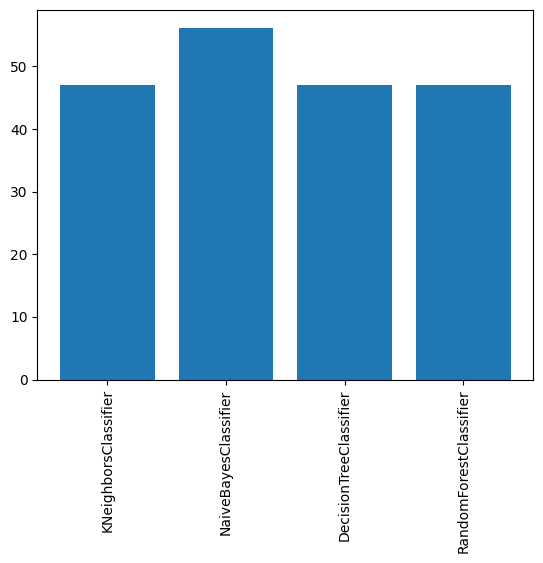

In [ ]:
plt.bar(df2['models'],df2['scores'])
plt.xticks(rotation=90)
plt.show()

In [ ]:
review=['the movie is very bad']
data1=vec.transform(review)
y_pred5=model1.predict(data1)
y_pred5
if y_pred5 == 1:
  print("Positive")
elif y_pred5 == 0:
  print("Neutral")
else:
  print("Negative")

Neutral
